# 04 — Política sugerida de reabastecimiento

El cuaderno combina la demanda prevista por SKU del cuaderno 02, segmentos descriptivos del cuaderno 03, el snapshot físico/en tránsito y los atributos logísticos. Produce una **recomendación para revisión humana**, no emite órdenes ni certifica disponibilidad en tienda. `EXIST_W11` es una etiqueta de la fuente, no una fecha de recepción del lote.

**Supuestos de la corrida:** `L = 13` semanas de tránsito y `R = 4` semanas de revisión. Por SKU, `DDLT = μ × L`, `SS = z × σ × √L`, `ROP = DDLT + SS`, `IP = existencias físicas + tránsito`, y `S = μ × (L + R) + SS`. Se sugiere pedir cuando `IP ≤ ROP`; la cantidad se redondea hacia arriba a cajas completas (`FACTOR`). Los niveles `z` se asignan por segmento y requieren validación de negocio; no son niveles de servicio observados.

La cobertura y semanas hasta reorden solo están definidas cuando `μ > 0`. Costos ausentes no se interpretan como gratuitos y se mantienen sin valorizar. Los resultados son una foto de los artefactos existentes: el snapshot no trae una fecha de corte certificada y las métricas de compra no demuestran ahorros, menos quiebres ni mejora causal del servicio. La aprobación y ejecución real ocurren fuera del modelo, con controles de Compras.

In [1]:
import os
import glob
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

if not os.environ.get("JAVA_HOME"):
    cand = (glob.glob(r"C:\Program Files\Microsoft\jdk-17*")
            + glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*")
            + glob.glob(os.path.expanduser(r"~\AppData\Local\Microsoft\jdk-17*")))
    if cand:
        os.environ["JAVA_HOME"] = cand[0]
        os.environ["PATH"] = os.path.join(cand[0], "bin") + os.pathsep + os.environ.get("PATH", "")

ROOT = "." if os.path.isdir("hadoop") else ".."
_hh = os.path.abspath(os.path.join(ROOT, "hadoop"))
if os.path.isdir(os.path.join(_hh, "bin")):
    os.environ["HADOOP_HOME"] = _hh
    os.environ["PATH"] = os.path.join(_hh, "bin") + os.pathsep + os.environ.get("PATH", "")

spark = (
    SparkSession.builder
    .appName("Starbucks-Reabastecimiento")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "2g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
PARQUET_DIR = os.path.join(ROOT, "data", "parquet")
print("Spark", spark.version, "| Parquet en:", PARQUET_DIR)

Spark 4.1.2 | Parquet en: ..\data\parquet


## 1. Integración de las fuentes

Unimos el **pronóstico por SKU** (demanda esperada y desviación) con el
**snapshot de inventario** (on-hand `EXIST_W11` + en tránsito `TRANSITO`) y los
**atributos logísticos** (costo, unidades por caja, cajas por pallet).

In [2]:
fc = spark.read.parquet(os.path.join(PARQUET_DIR, "forecast_sku"))

hist = (spark.read.parquet(os.path.join(PARQUET_DIR, "historico"))
        .select("SKU", "DESCRIPCION", "PROVEEDOR", "EXIST_W11", "TRANSITO")
        .withColumn("SKU", F.col("SKU").cast("string"))
        .dropDuplicates(["SKU"]))

inf = (spark.read.parquet(os.path.join(PARQUET_DIR, "inf"))
       .select("SKU", "COSTO_UNITARIO", "FACTOR", "CS_POR_PALLET")
       .withColumn("SKU", F.col("SKU").cast("string"))
       .dropDuplicates(["SKU"]))

seg = (spark.read.parquet(os.path.join(PARQUET_DIR, "segmentos_sku"))
       .select("SKU", "segmento", "tipologia")
       .withColumn("SKU", F.col("SKU").cast("string"))
       .dropDuplicates(["SKU"]))

base = (fc.join(hist, "SKU", "left").join(inf, "SKU", "left").join(seg, "SKU", "left")
        .fillna({"EXIST_W11": 0.0, "TRANSITO": 0.0,
                 "FACTOR": 1.0, "CS_POR_PALLET": 1.0, "sigma_semanal": 0.0,
                 "segmento": "Sin clasificar", "tipologia": "Sin clasificar"}))
print("SKUs integrados:", base.count())
base.show(5, truncate=30)


SKUs integrados: 436


+--------+--------------------+-------------------+-------------------+------------------------------+------------------------------+---------+--------+--------------+------+-------------+------------------------------+------------+
|     SKU|demanda_pred_semanal|      sigma_semanal|  demanda_hist_prom|                   DESCRIPCION|                     PROVEEDOR|EXIST_W11|TRANSITO|COSTO_UNITARIO|FACTOR|CS_POR_PALLET|                      segmento|   tipologia|
+--------+--------------------+-------------------+-------------------+------------------------------+------------------------------+---------+--------+--------------+------+-------------+------------------------------+------------+
|  101091| 0.05308331313056178|                0.0|                0.0| TINTA PARA PISTOLA DE PRECIOS|STARBUCKS CORPORATION Utileria|      0.0|     0.0|          1.66|     1|        128.0|Sin demanda observada (vali...|Intermittent|
|   10536|0.057973211698132396|                0.0|                0

## 2. Cálculo del punto de reorden con nivel de servicio diferenciado

Parámetros del negocio (ajustables):
- `L = 13` semanas (tránsito de 3 meses).
- `R = 4` semanas (periodo de revisión / frecuencia de pedido).

**Mejora (mezcla con la segmentación):** el nivel de servicio `z` ya no es único.
Se asigna según el **segmento** del SKU (resultado del notebook 03), de modo que
los productos críticos se protegen más que los obsoletos de baja rotación:

| Segmento | Nivel de servicio | z |
|---|---|---|
| Muy alta rotación / Críticos | 97.5 % | 1.96 |
| Alta rotación / Esenciales | 96.5 % | 1.81 |
| Rotación media / Regulares | 95 % | 1.65 |
| Baja rotación / Estacionales | 90 % | 1.28 |
| Sin rotación / Obsoletos | 85 % | 1.04 |

**Mejora operativa:** la cantidad a pedir se **redondea a cajas completas**
(múltiplos de `FACTOR`), de modo que el plan sea directamente ejecutable por el
área de compras (no se piden unidades sueltas).


In [3]:
L = 13                         
R = 4                                     

z_muy_baja, z_baja, z_media, z_alta, z_sin_demanda = 1.28, 1.65, 1.81, 1.96, 1.04
z_expr = (F.when(F.col("segmento") == "Rotacion alta", z_alta)
           .when(F.col("segmento") == "Rotacion media", z_media)
           .when(F.col("segmento") == "Rotacion baja", z_baja)
           .when(F.col("segmento") == "Rotacion muy baja", z_muy_baja)
           .when(F.col("segmento") == "Sin demanda observada (validar catalogo)", z_sin_demanda)
           .otherwise(z_baja))

rec = (base
    .withColumn("mu", F.col("demanda_pred_semanal"))
    .withColumn("sigma", F.col("sigma_semanal"))
    .withColumn("z_aplicado", z_expr)
    .withColumn("IP", F.col("EXIST_W11") + F.col("TRANSITO"))
    .withColumn("DDLT", F.col("mu") * L)
    .withColumn("SS", F.col("z_aplicado") * F.col("sigma") * F.sqrt(F.lit(float(L))))
    .withColumn("ROP", F.col("DDLT") + F.col("SS"))
    .withColumn("nivel_objetivo_S", F.col("mu") * (L + R) + F.col("SS"))
    .withColumn("pedir_ahora", F.when(F.col("IP") <= F.col("ROP"), 1).otherwise(0))
    .withColumn("faltante_unid", F.greatest(F.lit(0.0), F.col("nivel_objetivo_S") - F.col("IP")))
    .withColumn("cantidad_cajas",
                F.when(F.col("FACTOR") > 0, F.ceil(F.col("faltante_unid") / F.col("FACTOR")))
                 .otherwise(F.ceil(F.col("faltante_unid"))))
    .withColumn("cantidad_unid",
                F.when(F.col("FACTOR") > 0, F.col("cantidad_cajas") * F.col("FACTOR"))
                 .otherwise(F.col("cantidad_cajas")))
    .withColumn("cobertura_sem", F.when(F.col("mu") > 0, F.round(F.col("IP") / F.col("mu"), 1)).otherwise(F.lit(None)))
    .withColumn("semanas_hasta_pedido",
                F.when(F.col("mu") > 0, F.greatest(F.lit(0.0), F.round((F.col("IP") - F.col("ROP")) / F.col("mu"), 1)))
                 .otherwise(F.lit(None)))
    .withColumn(
        "valor_pedido_usd",
        F.when(
            F.col("COSTO_UNITARIO").isNotNull() & ~F.isnan("COSTO_UNITARIO"),
            F.round(F.col("cantidad_unid") * F.col("COSTO_UNITARIO"), 2),
        ),
    )
)

rec.select("SKU", "segmento", "z_aplicado", "mu", "IP", "ROP", "pedir_ahora",
           "cantidad_unid", "cantidad_cajas", "semanas_hasta_pedido", "valor_pedido_usd").show(10, truncate=30)

+--------+------------------------------+----------+--------------------+----+------------------+-----------+-------------+--------------+--------------------+----------------+
|     SKU|                      segmento|z_aplicado|                  mu|  IP|               ROP|pedir_ahora|cantidad_unid|cantidad_cajas|semanas_hasta_pedido|valor_pedido_usd|
+--------+------------------------------+----------+--------------------+----+------------------+-----------+-------------+--------------+--------------------+----------------+
|  101091|Sin demanda observada (vali...|      1.04| 0.05308331313056178| 0.0|0.6900830706973031|          1|            1|             1|                 0.0|            1.66|
|   10536|Sin demanda observada (vali...|      1.04|0.057973211698132396| 4.0|0.7536517520757211|          0|            0|             0|                56.0|             0.0|
|   10850|Sin demanda observada (vali...|      1.04| 0.05764662883137032| 0.0|0.7494061748078141|          1|      

## 3. Plan de pedidos prioritizado

Listamos los SKUs que deben **pedirse ahora** (posición de inventario por debajo
del punto de reorden), ordenados por urgencia y valor.

In [4]:
pedir = rec.filter(F.col("pedir_ahora") == 1)
n_total = rec.count()
n_pedir = pedir.count()
valor_total = pedir.agg(F.sum("valor_pedido_usd")).first()[0] or 0.0
print(f"SKUs a pedir AHORA: {n_pedir} de {n_total}  ({100*n_pedir/n_total:.1f}%)")
print(f"Valor total del pedido sugerido: ${valor_total:,.2f}")

(pedir.select("SKU", "DESCRIPCION", "mu", "IP", "ROP", "cantidad_unid",
              "cantidad_cajas", "valor_pedido_usd", "semanas_hasta_pedido")
      .orderBy(F.asc("semanas_hasta_pedido"), F.desc("valor_pedido_usd"))
      .show(15, truncate=35))

SKUs a pedir AHORA: 259 de 436  (59.4%)
Valor total del pedido sugerido: $117,873.42


+--------+-----------------------------------+--------------------+------+------------------+-------------+--------------+----------------+--------------------+
|     SKU|                        DESCRIPCION|                  mu|    IP|               ROP|cantidad_unid|cantidad_cajas|valor_pedido_usd|semanas_hasta_pedido|
+--------+-----------------------------------+--------------------+------+------------------+-------------+--------------+----------------+--------------------+
|11035352|VASO CALIENTE GRANDE 16   ( CAJA...|  10.502123419483182|   1.0| 172.4958614626929|          214|           214|        11654.44|                 0.0|
|    7360|CAFE ESPRESSO PARA MASTRENA  (Ca...|   48.41709147552335| 472.0| 687.4125621007856|          412|           103|        10707.88|                 0.0|
|11056480|TAPA CALIENTE GRANDE Y VENTI 16/...|   34.69177777213569| 291.0| 499.1747901369783|          347|           347|         7404.98|                 0.0|
|11104720|PAPEL MANTEQUILLA  9.5X9

## 4. SKUs que aún NO requieren pedido (mayor cobertura)

Útil para liberar capital: productos con inventario muy por encima del ROP.

In [5]:
(rec.filter((F.col("pedir_ahora") == 0) & (F.col("mu") > 0))
    .select("SKU", "DESCRIPCION", "mu", "IP", "ROP", "cobertura_sem", "semanas_hasta_pedido")
    .orderBy(F.desc("semanas_hasta_pedido"))
    .show(10, truncate=35))

+--------+-----------------------------------+--------------------+-----+------------------+-------------+--------------------+
|     SKU|                        DESCRIPCION|                  mu|   IP|               ROP|cobertura_sem|semanas_hasta_pedido|
+--------+-----------------------------------+--------------------+-----+------------------+-------------+--------------------+
|11070522|        "SCOOP 8"" HANDLE SS 1 TSP"| 0.05371265436484597|145.0|  2.45913433897023|       2699.6|              2653.8|
|11134074|BOLSA DE PAPEL WARNING PARA PAST...|  0.2826417805805669|544.0| 82.10044873035218|       1924.7|              1634.2|
|11120905|Pin Reconocimiento Level 200 (5 ...|0.057973211698132396| 96.0| 7.265955680718518|       1655.9|              1530.6|
|11052225|VASO cold VENTI COMPOSTABLE 20/2...| 0.04893524615415919| 71.0|0.6361582000040694|       1450.9|              1437.9|
|11120904|Pin Reconocimiento Level 100 (5 ...|0.057973211698132396| 85.0| 5.601156180163215|       1466.

## 5. Visualización: urgencia vs. valor del pedido

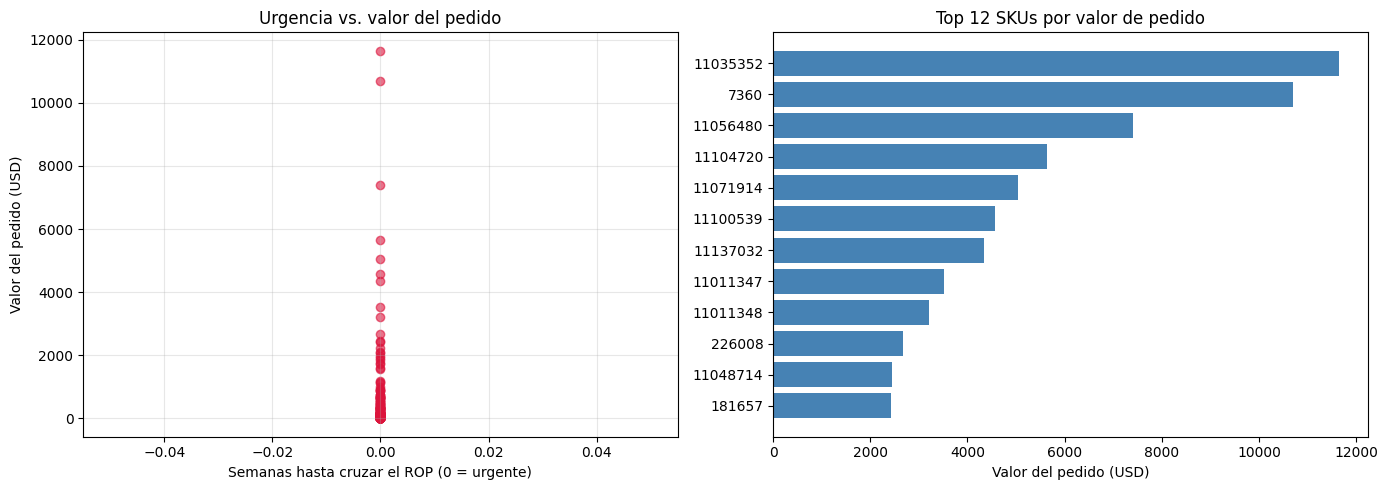

In [6]:
import matplotlib.pyplot as plt

pdf = (pedir.select("SKU", "semanas_hasta_pedido", "valor_pedido_usd", "cantidad_cajas")
       .toPandas())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(pdf["semanas_hasta_pedido"], pdf["valor_pedido_usd"], alpha=0.6, color="crimson")
ax[0].set_xlabel("Semanas hasta cruzar el ROP (0 = urgente)")
ax[0].set_ylabel("Valor del pedido (USD)")
ax[0].set_title("Urgencia vs. valor del pedido")
ax[0].grid(True, alpha=0.3)

top = pdf.sort_values("valor_pedido_usd", ascending=False).head(12)
ax[1].barh(top["SKU"].astype(str), top["valor_pedido_usd"], color="steelblue")
ax[1].set_xlabel("Valor del pedido (USD)")
ax[1].set_title("Top 12 SKUs por valor de pedido")
ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

## 6. Persistencia del plan de reabastecimiento

In [7]:
salida = rec.select(
    "SKU", "DESCRIPCION", "PROVEEDOR", "segmento", "tipologia",
    "mu", "sigma", "z_aplicado", "EXIST_W11", "TRANSITO",
    "IP", "DDLT", "SS", "ROP", "nivel_objetivo_S", "pedir_ahora",
    "cantidad_unid", "cantidad_cajas", "valor_pedido_usd",
    "cobertura_sem", "semanas_hasta_pedido",
    "FACTOR", "COSTO_UNITARIO",
)
salida.write.mode("overwrite").parquet(os.path.join(PARQUET_DIR, "plan_reabastecimiento"))
(salida.coalesce(1).write.mode("overwrite").option("header", True)
       .csv(os.path.join(ROOT, "data", "plan_reabastecimiento_csv")))
print("Plan guardado en parquet y CSV.")
spark.stop()
print("SparkSession finalizada.")


Plan guardado en parquet y CSV.


SparkSession finalizada.
